# 04 — ε Sensitivity: 5 methods × 4 envs × 5 ε values


In [1]:
import sys, os, time
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt

from envs import (CliffWalking, StochasticCliff,
                  CorridorCliff, StochasticCorridorCliff)
from agents import (run_sarsa, run_q_learning, run_expected_sarsa,
                    run_double_expected_sarsa, run_rr_expected_sarsa)
from utils import (multi_seed_run, smooth,
                   bootstrap_mean_ci, bootstrap_diff_ci, pairwise_table,
                   rollout_metrics, regret_to_convergence)

# ---- Run configuration ----

N_RUNS = 500
N_EPISODES = 100
EPS_DEFAULT = 0.1
ALPHA_DEFAULT = 0.3
SLIP = 0.2
RR_DELTA = 1.0   # RR-ES regret threshold used in most experiments

def sem(arr, axis=0):
    return arr.std(axis=axis, ddof=1) / np.sqrt(arr.shape[axis])

# ---- Environment factories ----
def env_det(seed=None):   return CliffWalking()
def env_stoch(seed=None): return StochasticCliff(slip_prob=SLIP, rng_seed=seed)
def env_corr(seed=None):  return CorridorCliff()
def env_scor(seed=None):  return StochasticCorridorCliff(slip_prob=SLIP, rng_seed=seed)

ENVS = {
    'Det Cliff':        env_det,
    'Stoch Cliff':      env_stoch,
    'Corr Cliff':       env_corr,
    'Stoch Corr Cliff': env_scor,
}

# ---- Method registry ----
METHODS = {
    'SARSA':          (run_sarsa,                {}),
    'Q-learning':     (run_q_learning,           {}),
    'Expected SARSA': (run_expected_sarsa,       {}),
    'Double ES':      (run_double_expected_sarsa, {}),
    f'RR-ES (δ={RR_DELTA})': (run_rr_expected_sarsa, {'delta': RR_DELTA}),
}

METHOD_COLORS = {
    'SARSA':              '#1f77b4',
    'Q-learning':         '#ff7f0e',
    'Expected SARSA':     '#2ca02c',
    'Double ES':          '#9467bd',
    f'RR-ES (δ={RR_DELTA})': '#d62728',
}
METHOD_MARKERS = {
    'SARSA':              'o',
    'Q-learning':         's',
    'Expected SARSA':     '^',
    'Double ES':          'v',
    f'RR-ES (δ={RR_DELTA})': 'D',
}


In [2]:
EPS_VALUES = np.array([0.05, 0.1, 0.15, 0.2, 0.3])

results = {env_name: {name: {'mean': np.zeros(len(EPS_VALUES)),
                              'sem':  np.zeros(len(EPS_VALUES))}
                      for name in METHODS}
           for env_name in ENVS}

t0 = time.time()
for env_name, env_fn in ENVS.items():
    print(f'\n=== {env_name} ===')
    for i, eps in enumerate(EPS_VALUES):
        for name, (fn, kw) in METHODS.items():
            ret = multi_seed_run(fn, env_fn, N_RUNS, N_EPISODES,
                                 alpha=ALPHA_DEFAULT, eps=eps,
                                 progress=True, desc=f'{name} ε={eps}', **kw)
            per_run = ret[:, -30:].mean(axis=1)
            results[env_name][name]['mean'][i] = per_run.mean()
            results[env_name][name]['sem'][i]  = per_run.std(ddof=1) / np.sqrt(N_RUNS)
print(f'total: {time.time()-t0:.0f}s')



=== Det Cliff ===


SARSA ε=0.05:   0%|          | 0/500 [00:00<?, ?it/s]

Q-learning ε=0.05:   0%|          | 0/500 [00:00<?, ?it/s]

Expected SARSA ε=0.05:   0%|          | 0/500 [00:00<?, ?it/s]

Double ES ε=0.05:   0%|          | 0/500 [00:00<?, ?it/s]

RR-ES (δ=1.0) ε=0.05:   0%|          | 0/500 [00:00<?, ?it/s]

... (95 outputs left out)

Expected SARSA ε=0.3:   0%|          | 0/500 [00:00<?, ?it/s]

Double ES ε=0.3:   0%|          | 0/500 [00:00<?, ?it/s]

RR-ES (δ=1.0) ε=0.3:   0%|          | 0/500 [00:00<?, ?it/s]

total: 4246s


In [3]:
safe = lambda s: s.replace(' ', '_').replace('(','').replace(')','').replace('=','_').replace('δ','delta')
np.savez('../results/data/04_epsilon_sweep.npz',
         eps_values=EPS_VALUES, n_runs=N_RUNS, alpha=ALPHA_DEFAULT,
         **{f'{safe(env_name)}__{safe(m_name)}__{stat}': results[env_name][m_name][stat]
            for env_name in results for m_name in results[env_name]
            for stat in ['mean', 'sem']})
print('saved')


saved


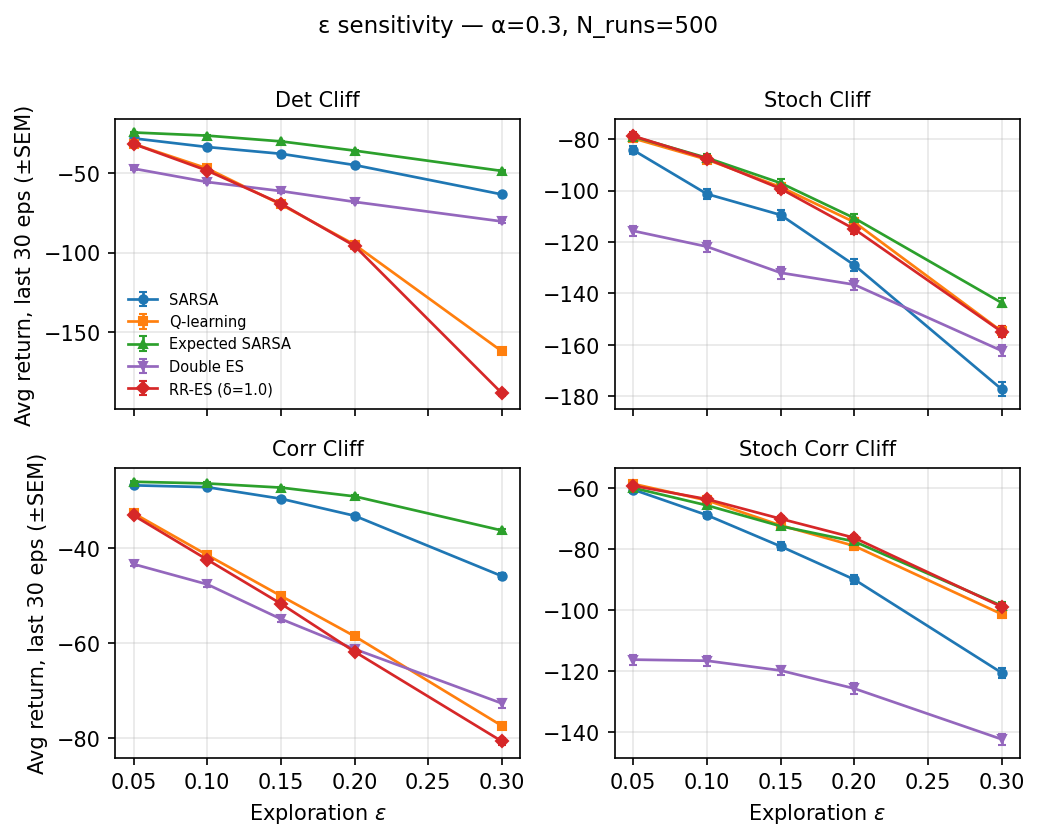

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(7, 5.5), dpi=150, sharex=True)
axes = axes.flatten()
for ax, (env_name, env_res) in zip(axes, results.items()):
    for m_name, d in env_res.items():
        ax.errorbar(EPS_VALUES, d['mean'], yerr=d['sem'],
                    label=m_name, color=METHOD_COLORS[m_name],
                    marker=METHOD_MARKERS[m_name],
                    linewidth=1.3, markersize=4, capsize=2)
    ax.set_title(env_name, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Avg return, last 30 eps (±SEM)')
axes[2].set_ylabel('Avg return, last 30 eps (±SEM)')
axes[2].set_xlabel(r'Exploration $\varepsilon$'); axes[3].set_xlabel(r'Exploration $\varepsilon$')
axes[0].legend(frameon=False, fontsize=7, loc='lower left')
plt.suptitle(f'ε sensitivity — α={ALPHA_DEFAULT}, N_runs={N_RUNS}', y=1.01, fontsize=11)
plt.tight_layout()
plt.savefig('../results/figures/04_epsilon_sweep.png', dpi=200, bbox_inches='tight')
plt.show()
